### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_QXPJCWURHXRB


## Preparations

### Import stuff

In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from scipy import signal
import h5py
import cv2
from scipy import ndimage as ndi
from roifile import roiread
import scipy.spatial.distance as dist
import scipy.cluster.hierarchy as sch
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
import matplotlib.patches as mpatches
from sklearn.decomposition import SparsePCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

import scanpy as sc
from anndata import AnnData
import leidenalg
import igraph as ig

from scipy.signal import butter, filtfilt, chirp
from scipy.stats import pearsonr, spearmanr

In [4]:
import sys
sys.path.append("./")
from monitor_flip_functions import compute_qi_custom, compute_response_index, make_plot

In [5]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

### load data

In [6]:
database = [
    {
        "name": "1",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250502_OGL_monitor_flip_analysis/20250121_rec8-rec9/response_table_combined.hdf5",
    },
    {
        "name": "2",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250502_OGL_monitor_flip_analysis/20250212_rec4-rec5/response_table_combined.hdf5",
    },
    {
        "name": "3",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250502_OGL_monitor_flip_analysis/20250318_rec9-rec10/response_table_combined.hdf5",
    },
    {
        "name": "4",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250502_OGL_monitor_flip_analysis/20250521_rec7-rec9/response_table_combined.hdf5",
    },
    {
        "name": "5",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250528_IGL_monitor_flip_analysis/20250212_rec2-rec3/response_table_combined.hdf5",
    },
    {
        "name": "6",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250528_IGL_monitor_flip_analysis/20250520_rec5-rec7/response_table_combined.hdf5",
    },
    {
        "name": "7",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250528_IGL_monitor_flip_analysis/20250520_rec8-rec9/response_table_combined.hdf5",
    },
    {
        "name": "8",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250528_IGL_monitor_flip_analysis/20250522_rec3-rec4/response_table_combined.hdf5",
    },
     {
        "name": "9",
         "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250528_IGL_monitor_flip_analysis/20250522_rec5-rec6/response_table_combined.hdf5",
    },
]

E = []
for (k, d) in enumerate(database):
    with pd.HDFStore(d["resp_table"], mode='r') as store:
        e = store["E"]
    e["recording"] = k
    e = e.reset_index().set_index(["recording", "neuron", "session", "trial", "time"])
    E.append(e)
E = pd.concat(E)

In [7]:
display(E)

y
recording neuron session trial time            
0         1      0       0     -2000        NaN
                               -1950        NaN
                               -1900        NaN
                               -1850        NaN
                               -1800        NaN
...                                         ...
8         155    5       9      18750 -1.417970
                                18800 -0.233748
                                18850  0.464617
                                18900 -0.158352
                                18950 -0.847058

[34272000 rows x 1 columns]

### Compute response

In [9]:
R = []
for rec in range(len(database)):
    df1 = E.xs(rec, level="recording")
    neuron_ids = df1.index.get_level_values("neuron").unique().sort_values()
    for n in neuron_ids:
        df2 = df1.xs(n, level="neuron")
        q1 = compute_qi_custom(df1, n, 2)
        q2 = compute_qi_custom(df1, n, 5)
        
        M = []
        for s in [1, 2, 4, 5]:
            df_filtered = df2.xs(s, level="session")
            mat = df_filtered.reset_index().pivot(index="trial", columns="time", values="y").to_numpy()
            mat = mat[:, 0:200]
            M.append(mat)
        M = np.hstack(M)
        M = M[~np.all(np.isnan(M), axis=1)] # remove trials with NaN values
        y_mean = np.nanmean(M, axis=0)

        r1 = compute_response_index(y_mean[200:400], cutoff=0.08, fs=20)
        r2 = compute_response_index(y_mean[600:800], cutoff=0.08, fs=20)

        if  (q1 > 0.24 and r1 > 0.6) or (q2 > 0.24 and r2 > 0.6):
            good = True
        else:
            good = False
        row = {
            "recording": rec,
            "region": database[rec]["region"],
            "neuron": n,
            "good": good,
        }
        for j, value in enumerate(y_mean):
            row[f"time_{j}"] = value
        R.append(row)

R = pd.DataFrame(R)

In [10]:
R = pd.DataFrame(R)
display(R)

,recording,region,neuron,good,time_0,time_1,time_2,time_3,time_4,time_5,...,time_790,time_791,time_792,time_793,time_794,time_795,time_796,time_797,time_798,time_799
0,0,OGL,1,True,-0.260765,-0.105565,0.046531,-0.198793,-0.015703,-0.029045,...,1.249449,1.257169,1.204909,1.397099,1.380041,1.275232,1.291227,1.296163,1.250495,1.334867
1,0,OGL,2,False,-1.420896,-1.380728,-1.332167,-1.412719,-1.457823,-1.442253,...,1.352590,1.288994,1.281787,1.346783,1.326102,1.235995,1.276723,1.297286,1.161653,1.249644
2,0,OGL,3,True,-1.361651,-1.448131,-1.388264,-1.462015,-1.470180,-1.442105,...,0.475339,0.643437,0.741191,0.234685,0.442145,0.670105,0.816256,0.819974,0.920078,1.215244
3,0,OGL,4,False,-1.450398,-1.519597,-1.259635,-1.395236,-1.446172,-1.191424,...,1.249269,1.216849,1.056623,1.059953,1.004428,1.030726,0.947560,0.836148,0.908323,0.940547
4,0,OGL,5,False,0.989353,1.254396,1.327575,1.089715,0.822304,0.767290,...,-0.365887,-0.555345,-0.888348,-1.029293,-0.879512,-1.127863,-0.897568,-0.762735,-0.507708,-0.734061
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,8,IGL,176,False,0.384106,0.348831,0.106594,0.014571,0.171919,0.087411,...,0.570635,0.006624,0.127840,0.511245,0.270663,0.511199,0.384550,0.629391,0.299628,-0.333441
1334,8,IGL,177,True,0.369082,0.333936,0.428675,0.394009,0.046025,0.187033,...,0.289731,0.256488,0.473804,0.597549,0.558918,0.472210,0.241232,0.108963,0.309119,0.516958
1335,8,IGL,178,True,-0.551695,-0.672312,-0.734733,-1.049439,-0.814104,-0.024008,...,1.057560,0.761890,0.440239,0.404533,0.788688,1.000730,0.608467,0.500419,0.485964,0.647111
1336,8,IGL,183,True,-0.091565,-0.053233,-0.024039,-0.082339,0.057786,0.221866,...,0.486412,0.532442,0.640355,0.697110,0.622841,0.400060,0.007892,0.123228,0.280279,0.145476


In [11]:
print(R.shape, R[R["good"]].shape)
print(R[(R["region"] == "OGL")].shape)
print(R[(R["region"] == "IGL")].shape)
print(R[R["good"] & (R["region"] == "OGL")].shape)
print(R[R["good"] & (R["region"] == "IGL")].shape)

(1338, 804) (511, 804)
(548, 804)
(790, 804)
(214, 804)
(297, 804)


### Leiden clustering

In [11]:
X = R[R["good"]].filter(regex="^time_").to_numpy()

# normalization
scaler = RobustScaler(with_centering=True, with_scaling=True, quantile_range=(1.0, 99.0), unit_variance=True)
X_norm = scaler.fit_transform(X.T).T
# scaler2 = StandardScaler()
# X_norm = scaler2.fit_transform(X_norm)

In [12]:
print(X.shape, R.shape)

(511, 800) (1338, 804)


In [13]:
# sparse PCA
S = []
S_reconst =[]
for i in range(4):
    D = X_norm[:, i * (200):(i + 1) * (200)]
    spca = SparsePCA(n_components=8, random_state=2025, alpha=1.0, tol=1e-5)
    D_spca = spca.fit_transform(D)
    D_reconstructed = np.dot(D_spca, spca.components_)
    S.append(D_spca)
    S_reconst.append(D_reconstructed)
S = np.hstack(S)
S_reconst = np.hstack(S_reconst)

In [14]:
# Leiden clulstering
adata = AnnData(S)
adata.obsm['X_pca'] = S
sc.pp.neighbors(adata, n_neighbors=8, metric='cosine', use_rep='X_pca', random_state=2025)
sc.tl.leiden(adata, resolution=0.8, flavor="igraph", random_state=2025)
cluster_ids = adata.obs["leiden"].cat.codes.to_numpy().copy()
print(cluster_ids.max())

2025-06-02 17:52:09.498194: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1748854329.513782  102626 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1748854329.518552  102626 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1748854329.530483  102626 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1748854329.530496  102626 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1748854329.530498  102626 computation_placer.cc:177] computation placer alr

11


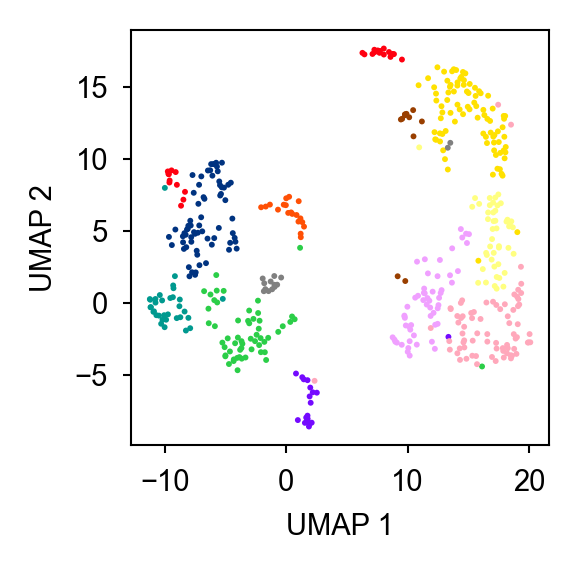

In [15]:
sc.pp.neighbors(adata, n_neighbors=8, metric='cosine', use_rep='X_pca', random_state=2025)
sc.tl.umap(adata, n_components=2, min_dist=0.2, spread=3.0)

alphabet_colors = [
    "#F0A0FF", "#0075DC", "#993F00", "#4C005C",
    "#2BCE48", "#FFCC99", "#808080", "#94FFB5", "#FFE100",
    "#C20088", "#003380", "#FFA405", "#FFA8BB", "#426600", "#FF0010",
    "#5EF1F2", "#00998F", "#E0FF66", "#740AFF", "#990000", "#FFFF80",
    "#FF5005"
]
alphabet_cmap = mpl.colors.ListedColormap(alphabet_colors, name='alphabet')
color_map = {i: alphabet_cmap(i-1) for i in np.unique(cluster_ids).astype("int")}

fig, ax = plt.subplots(figsize=(1.8,1.8), dpi=300)
X = adata.obsm['X_umap']
scatter = ax.scatter(X[:, 0], X[:, 1], c=cluster_ids, cmap=alphabet_cmap, s=2, alpha=1, lw=0)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
plt.show()

In [16]:
k = 0
for i, r in R.iterrows():
    if r["good"]:
        R.at[i, "cluster"] = int(cluster_ids[k])
        k += 1
    else:
        R.at[i, "cluster"] = -1

In [17]:
display(R)

,recording,region,neuron,good,time_0,time_1,time_2,time_3,time_4,time_5,...,time_791,time_792,time_793,time_794,time_795,time_796,time_797,time_798,time_799,cluster
0,0,OGL,1,True,-0.260765,-0.105565,0.046531,-0.198793,-0.015703,-0.029045,...,1.257169,1.204909,1.397099,1.380041,1.275232,1.291227,1.296163,1.250495,1.334867,0.0
1,0,OGL,2,False,-1.420896,-1.380728,-1.332167,-1.412719,-1.457823,-1.442253,...,1.288994,1.281787,1.346783,1.326102,1.235995,1.276723,1.297286,1.161653,1.249644,-1.0
2,0,OGL,3,True,-1.361651,-1.448131,-1.388264,-1.462015,-1.470180,-1.442105,...,0.643437,0.741191,0.234685,0.442145,0.670105,0.816256,0.819974,0.920078,1.215244,2.0
3,0,OGL,4,False,-1.450398,-1.519597,-1.259635,-1.395236,-1.446172,-1.191424,...,1.216849,1.056623,1.059953,1.004428,1.030726,0.947560,0.836148,0.908323,0.940547,-1.0
4,0,OGL,5,False,0.989353,1.254396,1.327575,1.089715,0.822304,0.767290,...,-0.555345,-0.888348,-1.029293,-0.879512,-1.127863,-0.897568,-0.762735,-0.507708,-0.734061,-1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,8,IGL,176,False,0.384106,0.348831,0.106594,0.014571,0.171919,0.087411,...,0.006624,0.127840,0.511245,0.270663,0.511199,0.384550,0.629391,0.299628,-0.333441,-1.0
1334,8,IGL,177,True,0.369082,0.333936,0.428675,0.394009,0.046025,0.187033,...,0.256488,0.473804,0.597549,0.558918,0.472210,0.241232,0.108963,0.309119,0.516958,5.0
1335,8,IGL,178,True,-0.551695,-0.672312,-0.734733,-1.049439,-0.814104,-0.024008,...,0.761890,0.440239,0.404533,0.788688,1.000730,0.608467,0.500419,0.485964,0.647111,9.0
1336,8,IGL,183,True,-0.091565,-0.053233,-0.024039,-0.082339,0.057786,0.221866,...,0.532442,0.640355,0.697110,0.622841,0.400060,0.007892,0.123228,0.280279,0.145476,5.0


### Save results

In [18]:
with pd.HDFStore(os.path.join(tmpdir, "result_combined.hdf5"), mode='w') as store:
    store.put('R', R)
    store.put('E', E)

### Mean of clusters

In [19]:
def plot_clustering2(df, cluster_cmap, stimulus_train, vmin=0, vmax=1, dt=0.05, figsize=(5,5), figsavename=None):
    def _plot_stimulus_train(axis, t, y):
        axis.plot(t, y, color="gray", lw=0.75)
        axis.set_xlim([t[0], t[-1]])
        axis.set_ylim([-0.25, 1.25])
        axis.axis("off")

    def _configure_axis(ax, label, yticks, ylim, labelpad=0, aspect=10):
        ax.set_aspect(aspect)
        ax.set_ylabel(label, labelpad=labelpad)
        ax.set_yticks(yticks)
        ax.set_ylim(ylim)
        ax.set_xticks([])
        ax.spines['top'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['left'].set_visible(False)

    df_sorted = df.sort_values(by='cluster')
    data = df_sorted.filter(regex="^time_").to_numpy()
    cluster_ids = df_sorted["cluster"]

    fig = plt.figure(figsize=figsize, dpi=300)
    gs = fig.add_gridspec(4, 6, width_ratios=[0.02, 0.3, 0.3, 0.3, 0.3, 0.04], height_ratios=[1, 0.04, 0.04, 0.04], wspace=0.05, hspace=0.1)

    # Cluster Color Annotations
    ax = fig.add_subplot(gs[0, 5])
    for k, i in enumerate(cluster_ids):
        ax.add_patch(mpatches.Rectangle((0, data.shape[0] - k - 1), 1, 1, color=cluster_cmap[i], lw=0))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, data.shape[0])
    ax.axis('off')

    # Plot Heatmaps
    for i in range(4):
        ax = fig.add_subplot(gs[0, 1 + i])
        ax.imshow(data[:, i * (200):(i + 1) * (200)], cmap="bone_r", vmin=vmin, vmax=vmax, aspect='auto', interpolation="nearest")
        ax.axis("off")
    
    # plot stimulus train
    t = np.arange(stimulus_train.size)
    _plot_stimulus_train(fig.add_subplot(gs[1, 1]), t, stimulus_train)
    _plot_stimulus_train(fig.add_subplot(gs[2, 1]), t, np.ones_like(t))
    _plot_stimulus_train(fig.add_subplot(gs[1, 2]), t, np.ones_like(t))
    _plot_stimulus_train(fig.add_subplot(gs[2, 2]), t, 1- stimulus_train)
    _plot_stimulus_train(fig.add_subplot(gs[1, 3]), t, stimulus_train)
    _plot_stimulus_train(fig.add_subplot(gs[2, 3]), t, np.ones_like(t))
    _plot_stimulus_train(fig.add_subplot(gs[1, 4]), t, np.ones_like(t))
    _plot_stimulus_train(fig.add_subplot(gs[2, 4]), t, 1- stimulus_train)

    # Draw the scale bar
    ax = fig.add_subplot(gs[3, 1])
    ax.plot([t[0], t[5000]], [-0.5,-0.5], color='black', lw=2)
    ax.text(t[2500], 0.8, '5 sec', color='black', ha='center', va='center', rotation=0)
    ax.set_xlim(t[0], t[-1])
    ax.set_ylim(-1, 1)
    ax.axis("off")

    ax = fig.add_subplot(gs[0, 0])
    _configure_axis(ax, "Neurons", [0, data.shape[0]], [data.shape[0], 0], labelpad=-10)
    ax = fig.add_subplot(gs[1, 0])
    _configure_axis(ax, "", [0, 1], [-0.25, 1.25])
    ax = fig.add_subplot(gs[2, 0])
    _configure_axis(ax, "", [0, 1], [-0.25, 1.25])

    if figsavename:
        plt.savefig(figsavename)
        print(f"Figure saved as {figsavename}")
    plt.show()

def plot_cluster_average(df, cluster_cmap, stimulus_train, ymin=0, ymax=1, figsize=(5,5), figsavename=None):
    def _plot_stimulus_train(axis, t, y):
        axis.plot(t, y, color="gray", lw=0.75)
        axis.set_xlim([t[0], t[-1]])
        axis.set_ylim([-0.25, 1.25])
        axis.axis("off")

    def _configure_axis(ax, label, yticks, ylim, labelpad=0, aspect=10):
        ax.set_aspect(aspect)
        ax.set_ylabel(label, labelpad=labelpad)
        ax.set_yticks(yticks)
        ax.set_ylim(ylim)
        ax.set_xticks([])
        ax.spines['top'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['right'].set_visible(False)

    def _configure_axis2(ax, label, labelpad=0, aspect=10):
        ax.set_aspect(aspect)
        ax.set_ylim(0,1)
        ax.set_xlim(0,1)
        ax.text(0.5, 0.5, label, ha="center", va="center")        
        ax.set_xticks([])
        ax.set_yticks([])
        for sp in ["top", "right", "bottom", "left"]:
            ax.spines[sp].set_visible(False)

    time_cols = [col for col in df.columns if col.startswith("time_")]
    means = df.groupby('cluster')[time_cols].mean()
    num_clusters = means.shape[0]
    t = np.arange(int(means.shape[1]/4))

    fig = plt.figure(figsize=figsize, dpi=300)
    gs = fig.add_gridspec(num_clusters+3, 6,
                          width_ratios=[0.05, 0.3, 0.3, 0.3, 0.3, 0.2],
                          height_ratios=[1,] * num_clusters + [0.5, 0.5, 0.5],
                          wspace=0.1, hspace=0.1)

    # Draw dendrogram
    D = dist.pdist(means, metric="cosine")
    Z = sch.linkage(D, method="complete")
    ax = fig.add_subplot(gs[0:num_clusters,5])
    with plt.rc_context({'lines.linewidth': 0.5}):
        sch.dendrogram(Z, orientation='left', ax=ax, no_labels=True, color_threshold=0, above_threshold_color='gray')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.invert_yaxis()
    ax.invert_xaxis()
    for sp in ["top", "right", "bottom", "left"]:
        ax.spines[sp].set_visible(False)

    # show cluster mean
    for (k, c) in enumerate(sorted(df["cluster"].unique())):
        for i in range(4):
            ax = fig.add_subplot(gs[k, i+1])
            y = means.loc[c][i * (200):(i + 1) * (200)]
            ax.plot(t, y, color="k", zorder=11, linewidth=1)
            ax.fill_between(t, ymin, y, color=cluster_cmap[c], zorder=10, alpha=0.8, linewidth=0, antialiased=True)
            ax.vlines([40, 120, 200, 240, 400], ymin, ymax, colors="lightgray", linestyles="dashed", lw=0.5)
            ax.set_xlim([t[0], t[-1]])
            ax.set_ylim([ymin, ymax])
            ax.axis("off")

    t = np.arange(stimulus_train.size)
    _plot_stimulus_train(fig.add_subplot(gs[num_clusters, 1]), t, stimulus_train)
    _plot_stimulus_train(fig.add_subplot(gs[num_clusters+1, 1]), t, np.ones_like(t))
    _plot_stimulus_train(fig.add_subplot(gs[num_clusters, 2]), t, np.ones_like(t))
    _plot_stimulus_train(fig.add_subplot(gs[num_clusters+1, 2]), t, 1- stimulus_train)
    _plot_stimulus_train(fig.add_subplot(gs[num_clusters, 3]), t, stimulus_train)
    _plot_stimulus_train(fig.add_subplot(gs[num_clusters+1, 3]), t, np.ones_like(t))
    _plot_stimulus_train(fig.add_subplot(gs[num_clusters, 4]), t, np.ones_like(t))
    _plot_stimulus_train(fig.add_subplot(gs[num_clusters+1, 4]), t, 1- stimulus_train)
    
    for i in range(num_clusters):
        ax = fig.add_subplot(gs[i, 0])
        _configure_axis2(ax, f"{i+1}", [0, 1])

    ax = fig.add_subplot(gs[num_clusters, 0])
    _configure_axis(ax, "", [0, 1], [-0.25, 1.25])
    ax = fig.add_subplot(gs[num_clusters+1, 0])
    _configure_axis(ax, "", [0, 1], [-0.25, 1.25])

    ax = fig.add_subplot(gs[num_clusters+2, 1])
    ax.plot([t[0], t[5000]], [-0.5,-0.5], color='black', lw=2)
    ax.text(t[2500], 0.5, '5 sec', color='black', ha='center', va='center', rotation=0)
    ax.set_xlim(t[0], t[-1])
    ax.set_ylim(-1, 1)
    ax.axis("off")

    if figsavename:
        plt.savefig(figsavename)
        print(f"Figure saved as {figsavename}")
    plt.show()

In [20]:
R2 = R[R["good"]].copy()
time_cols = [col for col in R2.columns if col.startswith("time_")]
X = R2[time_cols].values
scaler = RobustScaler(with_centering=True, with_scaling=True, quantile_range=(1.0, 99.0), unit_variance=True)
X_norm = scaler.fit_transform(X.T).T
# scaler2 = StandardScaler()
# X_norm = scaler2.fit_transform(X_norm)
R2_norm = R2.copy()
R2_norm[time_cols] = X_norm

Figure saved as /flash/ReiterU/tmp/tomo_JFYCGFUUAMXY/clustering.pdf


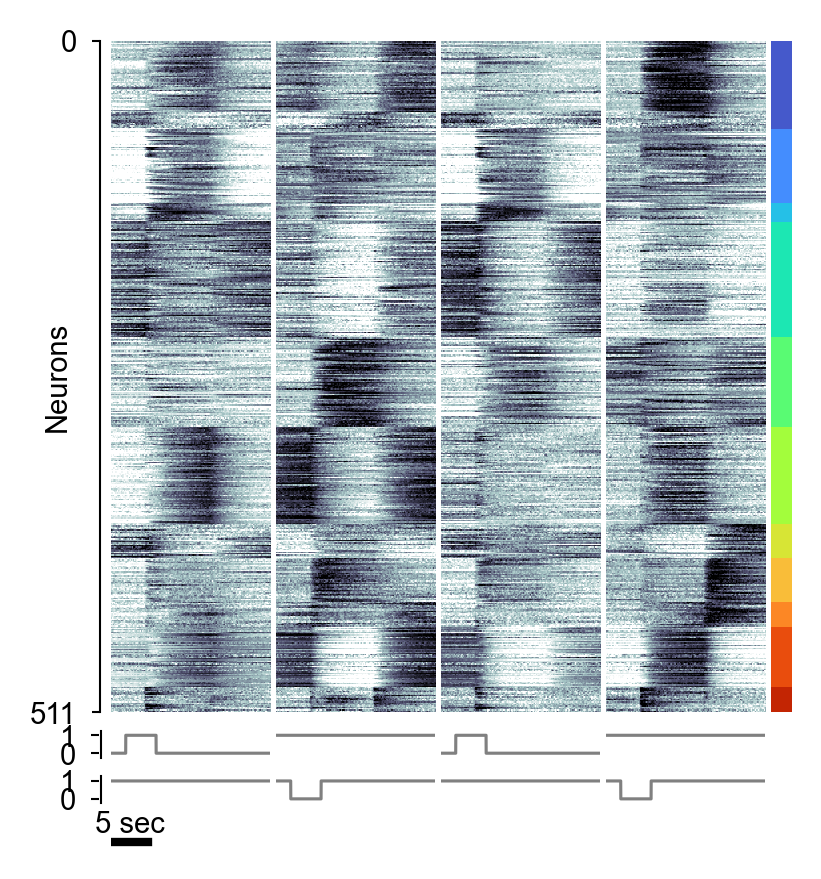

Figure saved as /flash/ReiterU/tmp/tomo_JFYCGFUUAMXY/cluster_mean.pdf


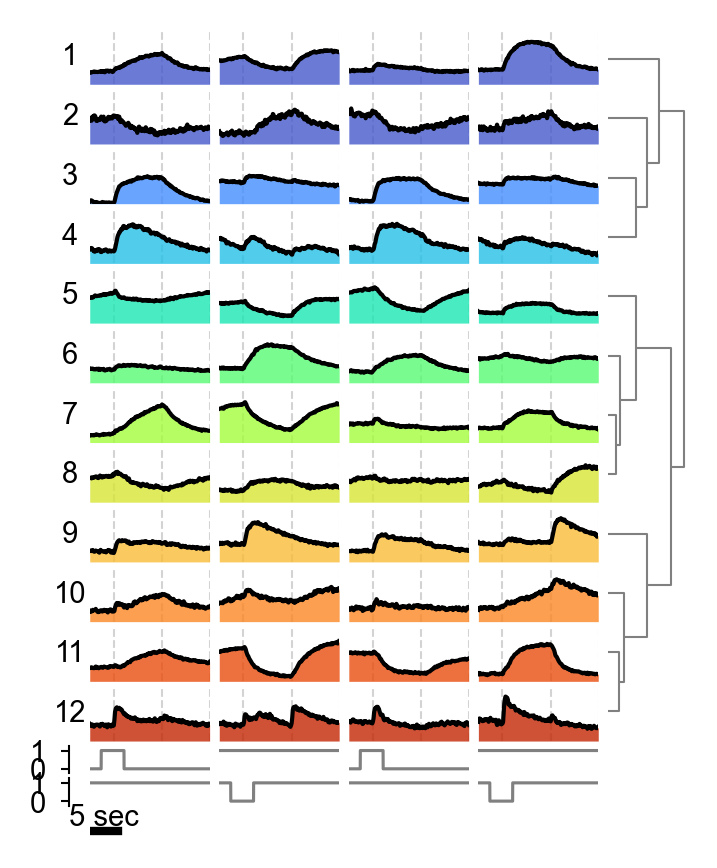

In [21]:
t = np.arange(21000) * 1e-3
y = np.zeros_like(t)
y[0:2000] = 0
y[2000:6000] = 1
y[6000:10000] = 0

cluster_ids = R2["cluster"]
orig_cmap = plt.get_cmap('turbo')
colors = orig_cmap(np.linspace(0.1, 0.9, 256))
new_cmap = mpl.colors.LinearSegmentedColormap.from_list('turbo_trimmed', colors, N=int(cluster_ids.max()))

color_map = {i: new_cmap(i-1) for i in np.unique(cluster_ids).astype("int")}

plot_clustering2(R2_norm, color_map, y, vmin=-1.5, vmax=3, figsize=(3,3.5), figsavename=os.path.join(tmpdir, "clustering.pdf"))
plot_cluster_average(R2_norm, color_map, y, ymin=-2.2, ymax=4, figsize=(2.7,3.5), figsavename=os.path.join(tmpdir, "cluster_mean.pdf"))

Number of OGL neurons: 214
Number of IGL neurons: 297


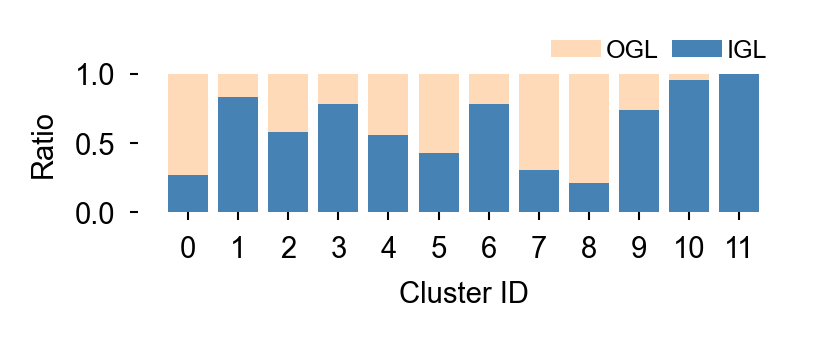

In [22]:
df1 = R2[R2["region"] == "OGL"]
df2 = R2[R2["region"] == "IGL"]
print("Number of OGL neurons:", df1.shape[0])
print("Number of IGL neurons:", df2.shape[0])

c1, c2 = [], []
for i in range(0, int(R2["cluster"].max())+1):
    c1.append(df1[df1["cluster"] == i].shape[0])
    c2.append(df2[df2["cluster"] == i].shape[0])
c1 = np.array(c1)
c2 = np.array(c2)

r1 = c1 / (c1 + c2)
r2 = c2 / (c1 + c2)
x = np.arange(0, r1.size)

fig, ax = plt.subplots(figsize=(2.8,0.6), dpi=300)
ax.bar(x, r1, bottom=r2, width=0.8, color="peachpuff", label="OGL")
ax.bar(x, r2, width=0.8, color="steelblue", label="IGL")
ax.set_xlim(-1,R["cluster"].max()+1)
ax.set_ylim(0,1)
ax.set_xlabel("Cluster ID")
ax.set_ylabel("Ratio")
ax.set_xticks(np.arange(0, R["cluster"].max()+1))
# ax.xaxis.set_tick_params(labelsize=6)
ax.legend(frameon=False, bbox_to_anchor=(0.6, 0.92), ncol=2, columnspacing=0.5, markerscale=1,  handletextpad=0.2, fontsize=6)
for sp in ["top", "right", "bottom", "left"]:
    ax.spines[sp].set_visible(False)

plt.savefig(os.path.join(tmpdir, "cluster_ratios.pdf"), bbox_inches='tight')
plt.show()

### Copy data to bucket

In [23]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250601_OGL_IGL_monitor_flip/"
print(f"mkdir -p {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir -p /bucket/ReiterU/OLdev/analysis/20250601_OGL_IGL_monitor_flip/
cp -r /flash/ReiterU/tmp/tomo_JFYCGFUUAMXY/* /bucket/ReiterU/OLdev/analysis/20250601_OGL_IGL_monitor_flip/
